# Tracy Gletsjer Data Download Notebook #   
This notebook downloads the following datasets for Tracy Gletsjer:
1. MEaSUREs-0781 Terminus Positions for Tracy Gletsjer
2. MEaSUREs-0766 Velocity Data for Tracy Gletsjer
3. IceBridge BedMachine Greenland, Version 7

Tracy Gletsjer is __Glacier #81__ in MEaSUREs-0766 AND MEaSUREs-0781 and __Glacier #84__ in Felikson Flowline Dataset

In [1]:
#import libraries and packages
import earthaccess
import geopandas as gpd
from pathlib import Path 
import os
import xarray as xr
import dask
import panel 
import pandas as pd
import matplotlib.pyplot as plt
import nisardev as nisar
import grimpfunc as grimp
from pathlib import Path
from dask.diagnostics import ProgressBar
ProgressBar().register()
dask.config.set(num_workers = 2) # avoid problems with too many open connections at NSIDC
panel.extension()
earthaccess.login()

In [2]:
# set data paths
data_dir = Path.home() / "Desktop" / "GrIS_Calving" / "data"
data_path = data_dir /"MEaSUREs_0781/JakobshavnIsbrae"

termini = gpd.read_file(data_path / "glacier_termini_v01.0.shp")
points = gpd.read_file(data_path / "glacier_points_v01.0.shp")
boxes = gpd.read_file(data_path / "glacier_boxes_v01.0.shp")

In [3]:
# select glacier: Tracy Gletsjer = 81
glacier_ID = 81
glacier_name = "TracyGletsjer"

# check selected glacier
print(points.loc[points["Glacier_ID"] == glacier_ID, ["Official_N", "Alternativ", "Glacier_ID"]])

# subset the termini data to grab specifically Store Gletsjer (Glacier ID 9) -- change name and Glacier_ID for different glaciers 
glacier_termini = termini[termini["Glacier_ID"] == glacier_ID].copy()

                     Official_N      Alternativ  Glacier_ID
161  Qeqertaarsuusarsuup Sermia  Tracy Gletsjer          81


In [4]:
#set/create output directory
outdir = data_dir / "MeASUREs_0781" / glacier_name / "processed"
outdir.mkdir(exist_ok=True, parents=True) #create directory if it doesn't exist

terminus_output_file = outdir / f"{glacier_name}Terminus.shp"

if not terminus_output_file.exists():
    glacier_termini.to_file(terminus_output_file)
    print(f"Saved: {terminus_output_file}")
else:
    print(f"File already exists, skipping: {terminus_output_file}")

File already exists, skipping: /Users/ssuhinin/Desktop/GrIS_Calving/data/MeASUREs_0781/TracyGletsjer/processed/TracyGletsjerTerminus.shp


In [5]:
import sys
import requests
import grimpfunc
from grimpfunc import cmr as grimp_cmr

CMR_URL = "https://cmr.earthdata.nasa.gov/search/granules.json"
PAGE_SIZE = 2000

def get_urls_fixed(short_name, version, time_start, time_end, bounding_box=None, polygon=None, filename_filter=None,verbose=False):
    params = {
        "provider": "NSIDC_CPRD",
        "sort_key[]": ["start_date", "producer_granule_id"],
        "page_size": PAGE_SIZE,
        "short_name": short_name,
        "version": version,
        "temporal[]": f"{time_start},{time_end}",
    }
    if bounding_box:
        params["bounding_box[]"] = bounding_box
    if polygon:
        params["polygon[]"] = polygon
    if filename_filter:
        params["producer_granule_id[]"] = filename_filter
        params["options[producer_granule_id][pattern]"] = "true"

    urls, headers = [], {}
    while True:
        r = requests.get(CMR_URL, params=params, headers=headers, timeout=60)
        if verbose:
            print(r.status_code, r.url)
        r.raise_for_status()
        results = r.json()
        urls += grimp_cmr.cmr_filter_urls(results)
        token = r.headers.get("CMR-Search-After")
        # Page not full (or no more pages) so done
        if len(results["feed"]["entry"]) < PAGE_SIZE or not token:
            break
        headers["CMR-Search-After"] = token
    return [str(x) for x in urls]

# Swap it in everywhere the library might look it up
grimp_cmr.get_urls = get_urls_fixed
grimpfunc.get_urls = get_urls_fixed
cu = sys.modules.get("grimpfunc.cmrUrls")
if cu is not None and hasattr(cu, "grimp"):
    cu.grimp.get_urls = get_urls_fixed

In [6]:
env = dict(GDAL_HTTP_COOKIEFILE = os.path.expanduser('~/.grimp_download_cookiejar.txt'),
            GDAL_HTTP_COOKIEJAR = os.path.expanduser('~/.grimp_download_cookiejar.txt'))
os.environ.update(env)

In [7]:
myUrls = grimp.cmrUrls(mode='subsetter')
display(myUrls.initialSearch(product='NSIDC-0766'))
myCogs = myUrls.getCogs(replace='vv', removeTiff=True)

BokehModel(combine_events=True, render_bundle={'docs_json': {'027e8a68-190b-4c6d-bf33-db03f05baf8b': {'version…

In [8]:
# load glacier terminus data from earlier 
terminus = gpd.read_file(terminus_output_file)
terminus = terminus.to_crs("EPSG:3413")

# define the bounding box for the velocity data download based on the terminus shapefile
minx, miny, maxx, maxy = terminus.total_bounds

# add 15 km margin/bugger around glacier termini
margin = 15000

bbox = {"minx": minx - margin, "maxx": maxx + margin, "miny": miny - margin, "maxy": maxy + margin}
print("bbox:", bbox)

bbox: {'minx': np.float64(-499584.6468000412), 'maxx': np.float64(-464245.34439992905), 'miny': np.float64(-1270135.6607000828), 'maxy': np.float64(-1234865.1500999928)}


In [9]:
# create a velocity series object with the COGs searched for above
velocity_series = nisar.nisarVelSeries()
velocity_series.readSeriesFromTiff(myCogs, url=True, readSpeed=False)

# subset to glacier bounding box
velocity_series.subSetVel(bbox)

/var/folders/q7/8k201bg52d33yzw350dwhgcm0000gp/T/ipykernel_10765/2689399059.py:6: DeprecationWarning: 
subSetVel deprecated. Use subsetVel
  velocity_series.subSetVel(bbox)


In [12]:
import xarray as xr
from pathlib import Path

# Set/create output directory
velocity_outdir = (
    data_dir / "MEaSUREs_0766" / glacier_name / "processed"
)
velocity_outdir.mkdir(exist_ok=True, parents=True)

# Directory for individual velocity batches
batch_dir = velocity_outdir / "velocity_batches"
batch_dir.mkdir(exist_ok=True, parents=True)

# Split velocity time series into batches
batch_size = 20
n_times = velocity_series.subset.sizes["time"]

failed_batches = []

for start in range(0, n_times, batch_size):
    end = min(start + batch_size, n_times)

    batch_file = batch_dir / f"velocity_{start:03d}_{end:03d}.nc"
    temp_file = batch_dir / f"velocity_{start:03d}_{end:03d}.partial.nc"

    # Skip batches that have already downloaded
    if batch_file.exists():
        print(f"Skipping existing batch: {start}-{end}")
        continue

    print(f"Downloading batch {start}-{end} of {n_times}")

    try:
        batch = velocity_series.subset.isel(
            time=slice(start, end)
        )

        # Save to temporary file first
        batch.to_netcdf(temp_file)

        # Rename after successful download
        temp_file.replace(batch_file)

        print(f"Saved: {batch_file.name}")

    except Exception as e:
        failed_batches.append((start, end))
        print(f"FAILED batch {start}-{end}: {e}")

print("\nDownload finished.")
print("Failed batches:", failed_batches)


Skipping existing batch: 0-20
Skipping existing batch: 20-40
Skipping existing batch: 40-60
Skipping existing batch: 60-80
Skipping existing batch: 80-100
Skipping existing batch: 100-120
Skipping existing batch: 120-140
Skipping existing batch: 140-160
Skipping existing batch: 160-180
Skipping existing batch: 180-200
Skipping existing batch: 200-220
Skipping existing batch: 220-240
Skipping existing batch: 240-260
Skipping existing batch: 260-280
Skipping existing batch: 280-300
Skipping existing batch: 300-320
Skipping existing batch: 320-340
Skipping existing batch: 340-360
Skipping existing batch: 360-380
Skipping existing batch: 380-400
Skipping existing batch: 400-420
Skipping existing batch: 420-440
Skipping existing batch: 440-460
[########################################] | 100% Completed | 14.98 s
Saved: velocity_460_480.nc
Skipping existing batch: 480-494

Download finished.
Failed batches: []


In [13]:

# Check downloaded velocity batches
expected_files = [
    batch_dir / f"velocity_{start:03d}_{min(start + batch_size, n_times):03d}.nc"
    for start in range(0, n_times, batch_size)
]

missing_batches = []
corrupt_batches = []
valid_batches = []

for file in expected_files:

    if not file.exists():
        missing_batches.append(file.name)
        continue

    try:
        with xr.open_dataset(file) as ds:
            ds.load()
            if ds.sizes["time"] == 0:
                raise ValueError("Empty time dimension")

        valid_batches.append(file.name)

    except Exception as e:
        corrupt_batches.append((file.name, str(e)))

print("Expected batches:", len(expected_files))
print("Valid batches:", len(valid_batches))
print("Missing batches:", len(missing_batches))
print("Unreadable batches:", len(corrupt_batches))

print("\nMissing:")
for file in missing_batches:
    print(file)

print("\nUnreadable:")
for file, error in corrupt_batches:
    print(file, error)

print("\nExisting batch sizes:")
for file in expected_files:
    if file.exists():
        print(
            file.name,
            round(file.stat().st_size / 1e6, 2),
            "MB"
        )


Expected batches: 25
Valid batches: 25
Missing batches: 0
Unreadable batches: 0

Missing:

Unreadable:

Existing batch sizes:
velocity_000_020.nc 7.62 MB
velocity_020_040.nc 7.62 MB
velocity_040_060.nc 7.62 MB
velocity_060_080.nc 7.62 MB
velocity_080_100.nc 7.62 MB
velocity_100_120.nc 7.62 MB
velocity_120_140.nc 7.62 MB
velocity_140_160.nc 7.62 MB
velocity_160_180.nc 7.62 MB
velocity_180_200.nc 7.62 MB
velocity_200_220.nc 7.62 MB
velocity_220_240.nc 7.62 MB
velocity_240_260.nc 7.62 MB
velocity_260_280.nc 7.62 MB
velocity_280_300.nc 7.62 MB
velocity_300_320.nc 7.62 MB
velocity_320_340.nc 7.62 MB
velocity_340_360.nc 7.62 MB
velocity_360_380.nc 7.62 MB
velocity_380_400.nc 7.62 MB
velocity_400_420.nc 7.62 MB
velocity_420_440.nc 7.62 MB
velocity_440_460.nc 7.62 MB
velocity_460_480.nc 7.62 MB
velocity_480_494.nc 5.34 MB


In [14]:
# Final velocity output file
velocity_output_file = (
    velocity_outdir / f"{glacier_name}VelocitySeries.nc")

# Ensure every batch is present and readable
if missing_batches or corrupt_batches:
    raise RuntimeError(
        "Some batches are missing or unreadable. "
        "Fix them before combining."
    )

# Open batches in chronological order
batch_files = expected_files

combined = xr.open_mfdataset(
    batch_files,
    combine="nested",
    concat_dim="time"
)

try:
    # Check total number of observations
    assert combined.sizes["time"] == n_times, (
        "Time dimension mismatch!"
    )

    # Save to temporary file
    temp_output = (
        velocity_outdir /
        f"{glacier_name}VelocitySeries.partial.nc"
    )

    combined.to_netcdf(temp_output)

finally:
    combined.close()

# Verify saved file
with xr.open_dataset(temp_output) as check:
    assert check.sizes["time"] == n_times

# Move verified file to final output path
temp_output.replace(velocity_output_file)

print(f"Saved combined velocity file: {velocity_output_file}")


[########################################] | 100% Completed | 102.45 ms
[########################################] | 100% Completed | 102.34 ms
[########################################] | 100% Completed | 101.69 ms
[########################################] | 100% Completed | 105.64 ms
[########################################] | 100% Completed | 104.48 ms
[########################################] | 100% Completed | 105.59 ms
[########################################] | 100% Completed | 105.63 ms
[########################################] | 100% Completed | 104.54 ms
[########################################] | 100% Completed | 104.12 ms
[########################################] | 100% Completed | 106.32 ms
[########################################] | 100% Completed | 105.61 ms
[########################################] | 100% Completed | 105.82 ms
[########################################] | 100% Completed | 103.61 ms
[########################################] | 100% Completed | 10

In [15]:
# load Greenland-wide BedMachine v7 dataset
bedmachine_path = data_dir / "BedMachine" / "BedMachineGreenland-v7.nc"
bedmachine = xr.open_dataset(bedmachine_path)

# inspect the dataset
bedmachine

<xarray.Dataset> Size: 4GB
Dimensions:    (x: 10218, y: 18346)
Coordinates:
  * x          (x) int32 41kB -652925 -652775 -652625 ... 879325 879475 879625
  * y          (y) int32 73kB -632675 -632825 -632975 ... -3384275 -3384425
Data variables:
    mapping    |S1 1B ...
    mask       (y, x) int8 187MB ...
    surface    (y, x) float32 750MB ...
    thickness  (y, x) float32 750MB ...
    bed        (y, x) float32 750MB ...
    errbed     (y, x) float32 750MB ...
    source     (y, x) int8 187MB ...
    dataid     (y, x) int8 187MB ...
    geoid      (y, x) float32 750MB ...
    rgi        (y, x) int8 187MB ...
Attributes: (12/19)
    Conventions:                 CF-1.7, ACDD-1.3
    title:                       BedMachine Greenland v7
    creator_name:                Mathieu Morlighem
    creator_email:               mathieu.morlighem@dartmouth.edu
    creator_institution:         Department of Earth and Planetary Sciences, ...
    product_version:             v7.0
    ...                          ...
    references:                  Morlighem M. et al., (2017), BedMachine v3: ...
    keywords:                    EARTH SCIENCE > CRYOSPHERE > GLACIERS/ICE SH...
    summary:                     This dataset contains a bed topography/bathy...
    time_coverage_start:         1970-01-01
    time_coverage_end:           2019-10-01
    nominal_year:                2008

In [16]:
# define the BedMachine bounding box for the bedmachine data based on the terminus/velocity data
bedmachine = bedmachine.sel(x=slice(bbox["minx"], bbox["maxx"]), y=slice(bbox["maxy"], bbox["miny"]))

# inspect subset
bedmachine

<xarray.Dataset> Size: 1MB
Dimensions:    (x: 235, y: 235)
Coordinates:
  * x          (x) int32 940B -499475 -499325 -499175 ... -464525 -464375
  * y          (y) int32 940B -1234925 -1235075 -1235225 ... -1269875 -1270025
Data variables:
    mapping    |S1 1B ...
    mask       (y, x) int8 55kB ...
    surface    (y, x) float32 221kB ...
    thickness  (y, x) float32 221kB ...
    bed        (y, x) float32 221kB ...
    errbed     (y, x) float32 221kB ...
    source     (y, x) int8 55kB ...
    dataid     (y, x) int8 55kB ...
    geoid      (y, x) float32 221kB ...
    rgi        (y, x) int8 55kB ...
Attributes: (12/19)
    Conventions:                 CF-1.7, ACDD-1.3
    title:                       BedMachine Greenland v7
    creator_name:                Mathieu Morlighem
    creator_email:               mathieu.morlighem@dartmouth.edu
    creator_institution:         Department of Earth and Planetary Sciences, ...
    product_version:             v7.0
    ...                          ...
    references:                  Morlighem M. et al., (2017), BedMachine v3: ...
    keywords:                    EARTH SCIENCE > CRYOSPHERE > GLACIERS/ICE SH...
    summary:                     This dataset contains a bed topography/bathy...
    time_coverage_start:         1970-01-01
    time_coverage_end:           2019-10-01
    nominal_year:                2008

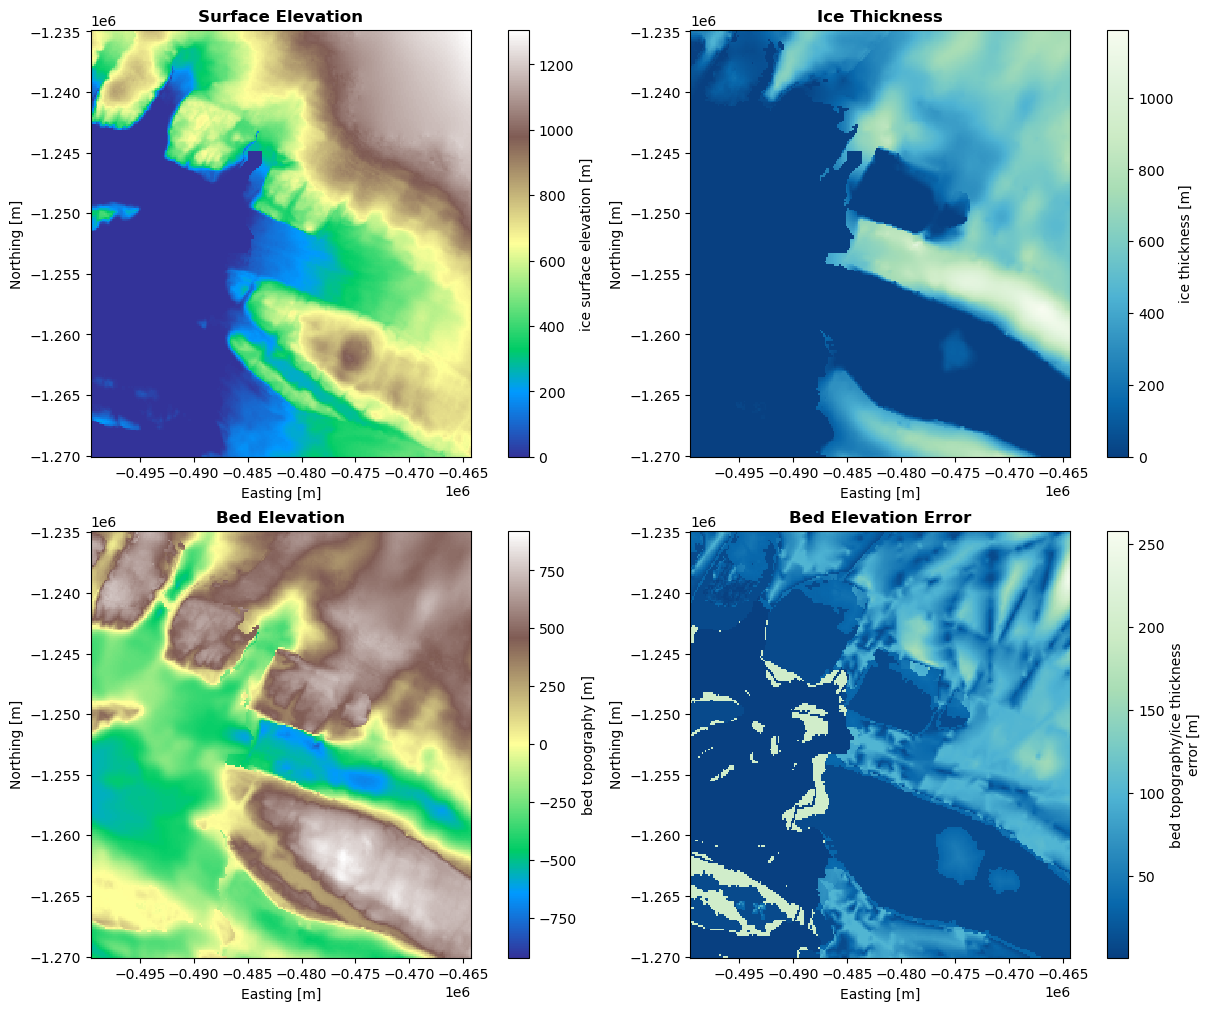

In [17]:
# plot verification of data
fig, ax = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

bedmachine["surface"].plot(ax=ax[0, 0], cmap="terrain")
ax[0, 0].set_title("Surface Elevation", fontweight = "bold")

bedmachine["thickness"].plot( ax=ax[0, 1], cmap="GnBu_r")
ax[0, 1].set_title("Ice Thickness", fontweight = "bold")

bedmachine["bed"].plot(ax=ax[1, 0], cmap="terrain")
ax[1, 0].set_title("Bed Elevation", fontweight = "bold")

bedmachine["errbed"].plot(ax=ax[1, 1], cmap="GnBu_r")
ax[1, 1].set_title("Bed Elevation Error", fontweight = "bold")


for a in ax.flat:
    a.set_xlabel("Easting [m]")
    a.set_ylabel("Northing [m]")
    a.ticklabel_format(axis="both", style="sci", scilimits=(6,6)) 


plt.show()

In [18]:
# set/create output directory
output_dir = data_dir / "BedMachine" / glacier_name / "processed"
output_file = os.path.join(output_dir, 'TracyGletsjerBedMachineV7.nc')

os.makedirs(output_dir, exist_ok=True)

bedmachine.to_netcdf(output_file)